# 06 — Neural networks: MLP, CharCNN, TinyTransformer

Three different view-points on the text: an MLP over the chi2-reduced TF-IDF +
stylometric vector (the classical joint layout), a character-level CNN over
raw Persian characters, and a from-scratch 2-layer Transformer over the word
vocabulary. Deployed checkpoints are evaluated **from disk, no retraining**, on
the leak-free held-out set with the shared `aitextd.metrics` battery.

In [1]:
import numpy as np
import pandas as pd
import torch
from scipy import sparse

from aitextd import loaders, metrics, paths, plots, registry, splits
from aitextd.features import STYLE_FEATURE_NAMES
from aitextd.training import encode_tokens, predict_probs

SEED = 42
RUN_TRAINING = False  # True: rerun the complete training procedure below (hours on CPU)

torch.manual_seed(SEED)
torch.set_num_threads(8)

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
heldout = splits.deployed_heldout_frame()
tokenized = splits.v1_tokens()
heldout_tokens = [tokenized[row] for row in heldout["v1_row"]]
heldout_joined = [" ".join(t) for t in heldout_tokens]
heldout_texts = heldout["text"].astype(str).tolist()
y_held = heldout["label_binary"].to_numpy()
style_table = pd.read_parquet(paths.DATA_DIR / "style_features_v2.parquet")
reports, probs_held = {}, {}
print(f"held-out set: {len(heldout)} documents "
      f"(human {int((y_held == 0).sum())} / AI {int((y_held == 1).sum())})")

held-out set: 4056 documents (human 1949 / AI 2107)


## Standard training procedure (complete, flag-guarded)

The **complete** procedures for all three networks, exactly as executed for
the deployed checkpoints: the MLP over the chi2-reduced TF-IDF + style joint
layout, the CharCNN over a character vocabulary built from the raw v1 texts,
and the TinyTransformer over the shared word vocabulary — each fitted with
`fit_classifier` and saved in the loader format.

**Not executed here** (`RUN_TRAINING = False`): the deployed checkpoints
provide the numbers below, and the evaluation cells run unchanged either way.

In [ ]:
if RUN_TRAINING:
    import joblib

    from sklearn.compose import ColumnTransformer
    from sklearn.feature_selection import SelectKBest, chi2

    from aitextd.architectures import MLPClassifier, TextCNNClassifier, TinyTransformerClassifier
    from aitextd.training import build_vocab, fit_classifier, save_checkpoint

    indices = joblib.load(paths.DATA_DIR / "split_indices.joblib")
    processed = pd.read_csv(paths.PROCESSED_CSV, usecols=["text", "aiGenerated"])
    y_all = processed["aiGenerated"].to_numpy()
    texts_all = processed["text"].astype(str).to_numpy()
    train_idx, test_idx = indices["train_idx"], indices["test_idx"]

    training_info = {
        "totalSamples": len(train_idx) + len(test_idx), "trainSamples": len(train_idx),
        "testSamples": len(test_idx), "testSplitRatio": 0.2,
        "randomSeed": SEED, "dataset": "persian_ai_generated_final.csv + blogs.csv",
    }

    # --- MLP over the chi2-reduced TF-IDF + style joint layout -----------------
    CHI2_K, HIDDEN_DIMS, MLP_DROPOUT = 10_000, (512, 128), 0.3
    X_v1 = joblib.load(paths.TFIDF_X_JOBLIB)
    selector = ColumnTransformer([
        ("tfidf_select", SelectKBest(chi2, k=CHI2_K), slice(0, tfidf_dim)),
        ("style", "passthrough", slice(tfidf_dim, None)),
    ], sparse_threshold=1.0).fit(X_v1[train_idx], y_all[train_idx])
    X_train_mlp = torch.tensor(selector.transform(X_v1[train_idx]).toarray(), dtype=torch.float32)
    X_test_mlp = torch.tensor(selector.transform(X_v1[test_idx]).toarray(), dtype=torch.float32)
    mlp_config = {
        "input_dim": int(X_train_mlp.shape[1]), "hidden_dims": list(HIDDEN_DIMS),
        "dropout": MLP_DROPOUT, "style_feature_count": int(X_v1.shape[1] - tfidf_dim), "chi2_k": CHI2_K,
    }
    print("training mlp ...", flush=True)
    mlp, _ = fit_classifier(
        MLPClassifier(X_train_mlp.shape[1], HIDDEN_DIMS, MLP_DROPOUT),
        X_train_mlp, y_all[train_idx], X_test_mlp, y_all[test_idx], epochs=6, batch_size=128,
    )
    save_checkpoint(paths.model_path("mlpModel.pt"), mlp, selector=selector, config=mlp_config)
    registry.refresh_entry(
        "mlp", metrics.evaluate(y_all[test_idx], predict_probs(mlp, X_test_mlp)),
        {**training_info, "featureCount": int(X_train_mlp.shape[1])},
    )

    # --- CharCNN over raw characters -------------------------------------------
    char_vocab = build_vocab(texts_all[train_idx], max_size=1000, min_freq=2)
    charcnn_config = {
        "embed_dim": 64, "n_filters": 128, "kernel_sizes": [3, 4, 5],
        "dropout": 0.3, "pad_idx": 0, "unk_idx": 1, "max_len": 512,
    }
    X_train_char = encode_tokens([list(t) for t in texts_all[train_idx]], char_vocab, 512)
    X_test_char = encode_tokens([list(t) for t in texts_all[test_idx]], char_vocab, 512)
    print("training charcnn ...", flush=True)
    charcnn, _ = fit_classifier(
        TextCNNClassifier(len(char_vocab), 64, 128, (3, 4, 5), pad_idx=0, dropout=0.3),
        X_train_char, y_all[train_idx], X_test_char, y_all[test_idx], epochs=4, batch_size=128,
    )
    save_checkpoint(paths.model_path("charcnnModel.pt"), charcnn, vocab=char_vocab, config=charcnn_config)
    registry.refresh_entry(
        "charcnn", metrics.evaluate(y_all[test_idx], predict_probs(charcnn, X_test_char)),
        {**training_info, "featureCount": len(char_vocab)},
    )

    # --- TinyTransformer over the shared word vocabulary -----------------------
    WORD_MAX_LEN, WORD_VOCAB = 200, 30_000
    tt_vocab = build_vocab([tokenized[i] for i in train_idx], max_size=WORD_VOCAB)
    tt_config = {
        "embed_dim": 128, "n_layers": 2, "n_heads": 4, "ff_dim": 256,
        "max_len": WORD_MAX_LEN, "pad_idx": 0, "unk_idx": 1, "dropout": 0.3,
    }
    X_train_tt = encode_tokens([tokenized[i] for i in train_idx], tt_vocab, WORD_MAX_LEN)
    X_test_tt = encode_tokens([tokenized[i] for i in test_idx], tt_vocab, WORD_MAX_LEN)
    print("training tinytransformer ...", flush=True)
    tinytransformer, _ = fit_classifier(
        TinyTransformerClassifier(
            len(tt_vocab), 128, 2, 4, 256, WORD_MAX_LEN, pad_idx=0, dropout=0.3,
        ),
        X_train_tt, y_all[train_idx], X_test_tt, y_all[test_idx], epochs=3, batch_size=32,
    )
    save_checkpoint(paths.model_path("tinyTransformerModel.pt"), tinytransformer, vocab=tt_vocab, config=tt_config)
    registry.refresh_entry(
        "tinytransformer", metrics.evaluate(y_all[test_idx], predict_probs(tinytransformer, X_test_tt)),
        {**training_info, "featureCount": len(tt_vocab)},
    )
    print("all three retrained — the evaluation cells below reload them from disk")
else:
    print("RUN_TRAINING=False — the deployed checkpoints are used below")

In [3]:
mlp = loaders.load_mlp_model({"filename": "mlpModel.pt"})
# serving layout: TF-IDF over tokenized text + the style columns the checkpoint
# was fit on, chi2-reduced by the selector stored inside the checkpoint
n_style = mlp["config"].get("style_feature_count", len(STYLE_FEATURE_NAMES))
style = heldout[["doc_id"]].merge(style_table, on="doc_id")[
    STYLE_FEATURE_NAMES[:n_style]
].to_numpy()
X_joint = sparse.hstack([mlp["vectorizer"].transform(heldout_joined), style], format="csr")
X_mlp = torch.tensor(mlp["selector"].transform(X_joint).toarray(), dtype=torch.float32)
probs_held["mlp"] = predict_probs(mlp["model"], X_mlp)
reports["mlp"] = metrics.evaluation_report(y_held, probs_held["mlp"])
print("evaluated mlp")

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


evaluated mlp


In [4]:
charcnn = loaders.load_charcnn_model({"filename": "charcnnModel.pt"})
# characters of the raw text, exactly the serving encoding
X_char = encode_tokens([list(t) for t in heldout_texts], charcnn["vocab"], charcnn["config"]["max_len"])
probs_held["charcnn"] = predict_probs(charcnn["model"], X_char)
reports["charcnn"] = metrics.evaluation_report(y_held, probs_held["charcnn"])
print("evaluated charcnn")

evaluated charcnn


In [5]:
tinytransformer = loaders.load_tinytransformer_model({"filename": "tinyTransformerModel.pt"})
X_tt = encode_tokens(heldout_tokens, tinytransformer["vocab"], tinytransformer["config"]["max_len"])
probs_held["tinytransformer"] = predict_probs(tinytransformer["model"], X_tt)
reports["tinytransformer"] = metrics.evaluation_report(y_held, probs_held["tinytransformer"])
print("evaluated tinytransformer")

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


evaluated tinytransformer


In [6]:
metrics.evaluation_table(reports, metrics.RANKING_COLUMNS)

,roc_auc,pr_auc,pauc_5,tpr_at_fpr_1,tpr_at_fpr_5,fpr_at_tpr_90
model,,,,,,
mlp,0.9999,0.9999,0.9987,0.9986,1.0000,0.0000
charcnn,0.9998,0.9998,0.9959,0.9948,0.9991,0.0000
tinytransformer,0.9989,0.9990,0.9872,0.9881,0.9967,0.0005


In [7]:
metrics.evaluation_table(reports, metrics.THRESHOLD_COLUMNS)

,accuracy,balanced_accuracy,macro_f1,mcc,kappa,precision,recall,f1,fpr
model,,,,,,,,,
mlp,0.9956,0.9955,0.9956,0.9911,0.9911,0.9939,0.9976,0.9957,0.0067
charcnn,0.9788,0.9796,0.9788,0.9585,0.9576,1.0000,0.9592,0.9792,0.0000
tinytransformer,0.9892,0.9892,0.9891,0.9783,0.9783,0.9910,0.9881,0.9895,0.0097


In [8]:
metrics.evaluation_table(reports, metrics.CALIBRATION_COLUMNS)

,ece,ace,mce,brier,nll,calibration_slope,calibration_intercept
model,,,,,,,
mlp,0.0037,0.0033,0.7741,0.0035,0.0132,0.8904,-1.2166
charcnn,0.0317,0.0322,0.7338,0.0168,0.0608,1.8091,4.8929
tinytransformer,0.0048,0.0019,0.3019,0.0087,0.0360,0.7798,0.0926


<Axes: title={'left': 'Neural networks — leak-free held-out set'}>

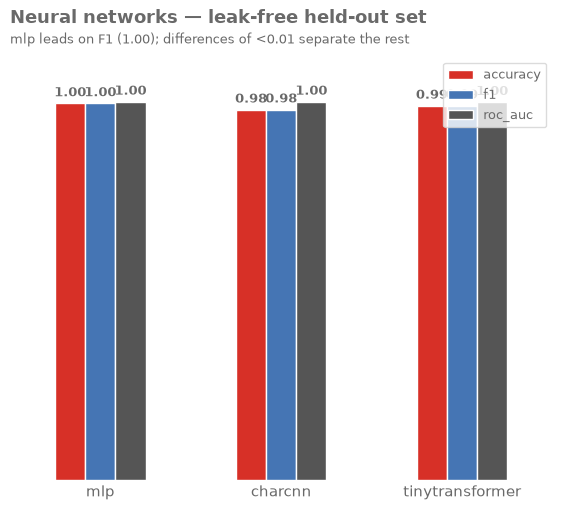

In [9]:
plots.metric_bars(reports, "Neural networks — leak-free held-out set")

<Axes: title={'center': 'mlp'}, xlabel='prediction'>

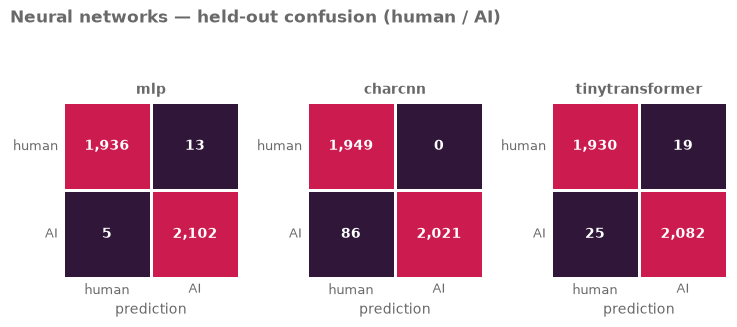

In [10]:
plots.confusion_grid(reports, "Neural networks — held-out confusion (human / AI)")

<Axes: title={'left': 'Neural networks — ROC, low-FPR region'}, xlabel='False Positive Rate (log scale)', ylabel='True Positive Rate'>

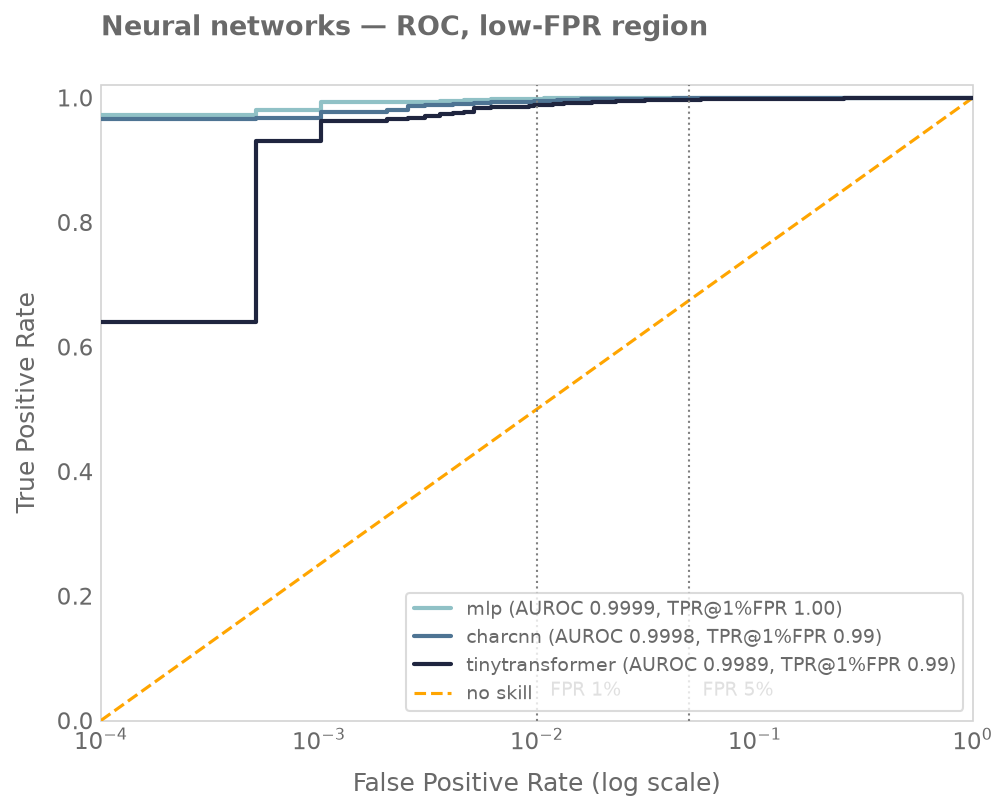

In [11]:
plots.roc_curves_log(y_held, probs_held, "Neural networks — ROC, low-FPR region")

<Axes: title={'left': 'mlp\nECE 0.004'}, ylabel='empirical accuracy'>

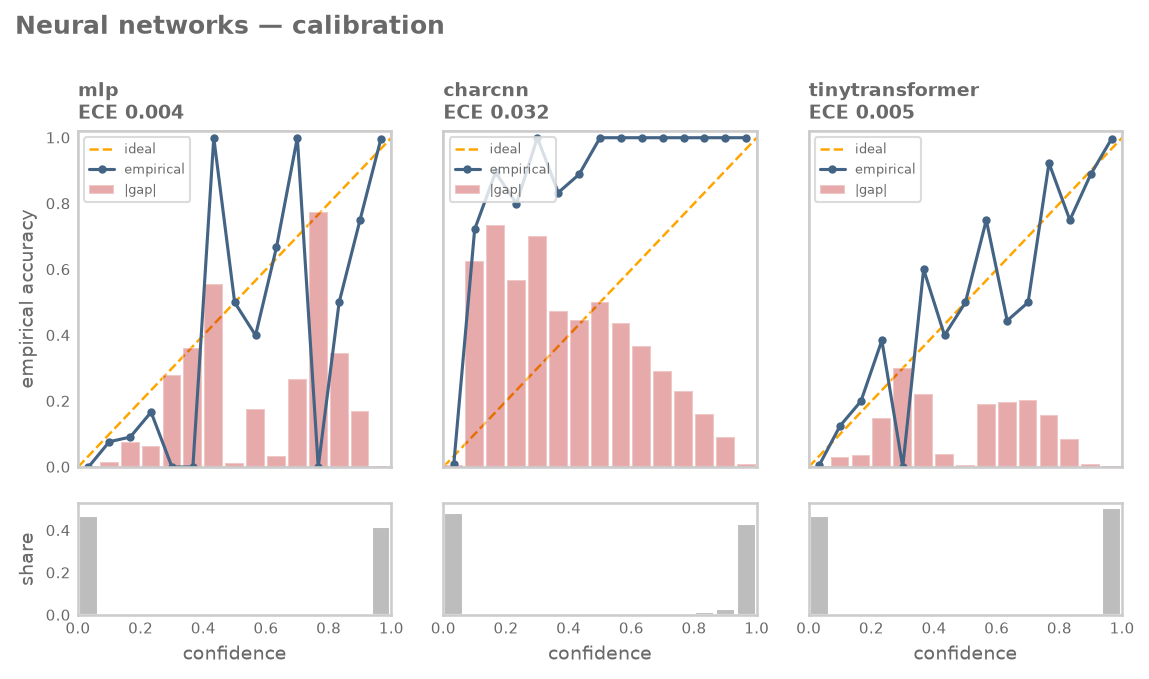

In [12]:
plots.reliability_grid(y_held, probs_held, title="Neural networks — calibration")

<Axes: title={'left': 'mlp'}, xlabel='AI probability', ylabel='density'>

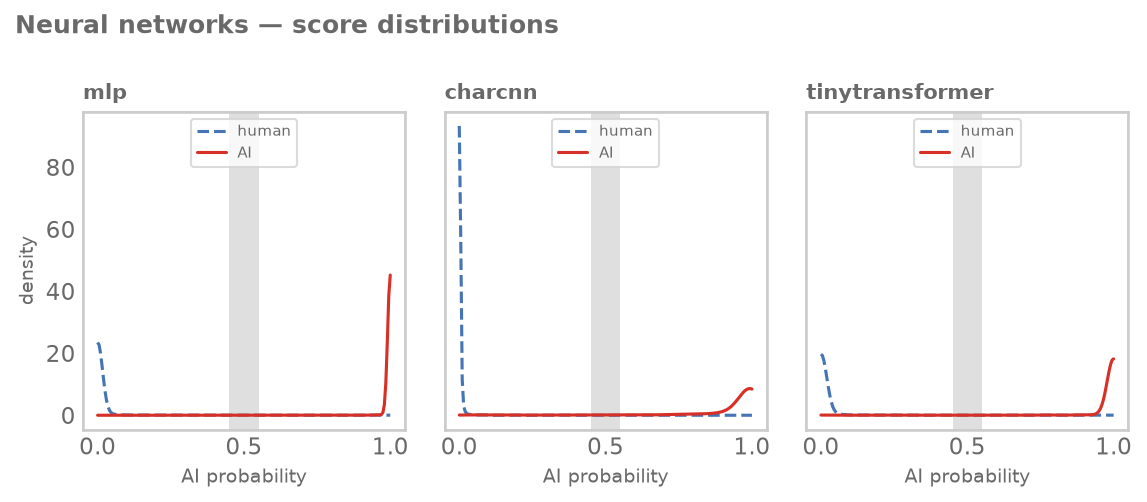

In [13]:
plots.score_distributions(y_held, probs_held, "Neural networks — score distributions")

## Summary

- The MLP consumes the same joint feature layout as the classical family
  (notebook 02); CharCNN and TinyTransformer read the text itself.
- Compare against notebooks 02/03 to see whether architecture or feature view
  drives the difference — the evaluation set is identical.